# SuperFlex: visual geometry laboratory
Recreates analytic demonstrations only not the neural model or published benchmarks. The main reference is Tavernini *et al.*, *SuperFlex*, Eqs. (1)-(11), Appendices A and B. [Official implementation](https://github.com/GabrielTavernini/superflex).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.special import expit
from scipy.optimize import brentq
OUT=Path('assets'); OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.size':11,'axes.titlesize':12,'savefig.dpi':180})
def spow(x,a): return np.sign(x)*np.abs(x)**a
def surface(s=(1,1,1),eps=(1,1),n=60,m=90):
    eta,om=np.meshgrid(np.linspace(-np.pi/2,np.pi/2,n),np.linspace(-np.pi,np.pi,m),indexing='ij')
    e1,e2=eps; sx,sy,sz=s; c=spow(np.cos(eta),e1)
    return np.stack((sx*c*spow(np.cos(om),e2),sy*c*spow(np.sin(om),e2),sz*spow(np.sin(eta),e1)),axis=-1)
def qcan(X,s=(1,1,1),eps=(1,1)):
    x,y,z=np.moveaxis(np.asarray(X,dtype=float),-1,0)
    e1,e2=eps; a,b,c=s
    return (np.abs(x/a)**(2/e2)+np.abs(y/b)**(2/e2))**(e2/e1)+np.abs(z/c)**(2/e1)
def taper(X,tx=0,ty=0,sz=1):
    Y=np.array(X,copy=True);z=Y[...,2].copy()
    Y[...,0]*=1+tx*z/sz;Y[...,1]*=1+ty*z/sz
    return Y
def untaper(X,tx=0,ty=0,sz=1):
    Y=np.array(X,copy=True);z=Y[...,2].copy()
    Y[...,0]/=1+tx*z/sz;Y[...,1]/=1+ty*z/sz
    return Y
def bend_z(X,k=0,alpha=0):
    """Forward circular bend about z, consistent with the inverse in paper Appendix A."""
    Y=np.array(X,copy=True)
    if abs(k)<1e-12:return Y
    x,y,z=np.moveaxis(Y,-1,0);c,s=np.cos(alpha),np.sin(alpha)
    a=x*c+y*s;b=-x*s+y*c;R=1/k
    ap=R-(R-a)*np.cos(k*z);zp=(R-a)*np.sin(k*z)
    Y[...,0]=ap*c-b*s;Y[...,1]=ap*s+b*c;Y[...,2]=zp
    return Y
def equal3d(ax,lim=1.65):
    ax.set(xlim=(-lim,lim),ylim=(-lim,lim),zlim=(-lim,lim))
    ax.set_box_aspect((1,1,1));ax.view_init(23,-59)
    ax.set_xlabel('x');ax.set_ylabel('y');ax.set_zlabel('z');ax.tick_params(labelsize=6)
def plot3d(ax,X,color='#468ab4'):
    ax.plot_surface(X[...,0],X[...,1],X[...,2],rstride=2,cstride=2,color=color,linewidth=0,shade=True)
    equal3d(ax)
def save(fig,name):
    fig.savefig(OUT/('demo_'+name+'.png'),bbox_inches='tight');plt.show()
X=surface(eps=(.35,.7));assert np.max(np.abs(qcan(X,eps=(.35,.7))-1))<1e-9
print('Canonical equation verified. GPU not required.')

Canonical equation verified. GPU not required.


## 1. Canonical superquadric
The paper's superellipsoid implicit function is
$$q_{can}(x,y,z)=\left(\left|\frac{x}{s_x}\right|^{2/\epsilon_2}+\left|\frac{y}{s_y}\right|^{2/\epsilon_2}\right)^{\epsilon_2/\epsilon_1}+\left|\frac{z}{s_z}\right|^{2/\epsilon_1}=1.$$
Here $\epsilon_1$ controls the meridional profile and $\epsilon_2$ controls the horizontal cross-section; scale $s$ elongates the axes. Smaller exponents create squarer silhouettes.

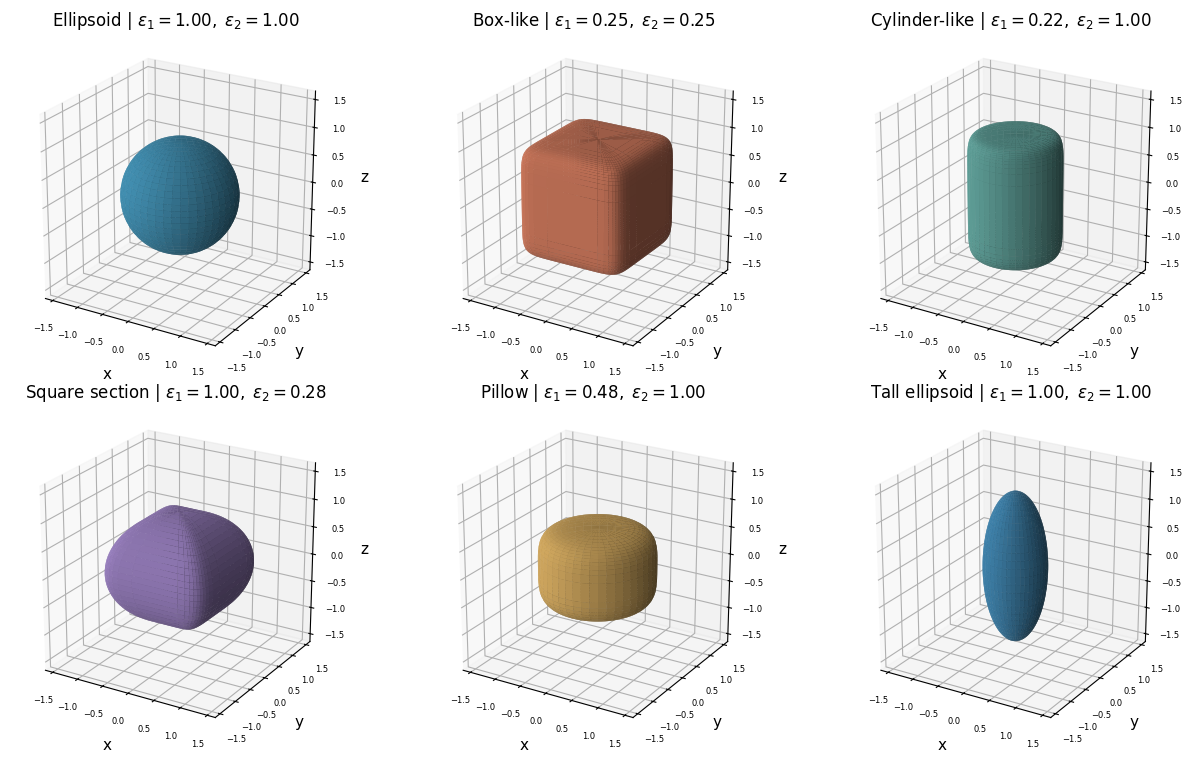

In [2]:
cases=[('Ellipsoid',(1,1),(1,1,1)),('Box-like',(.25,.25),(1,1,1)),('Cylinder-like',(.22,1),(.8,.8,1.1)),('Square section',(1,.28),(1,1,1)),('Pillow',(.48,1),(1,1,.72)),('Tall ellipsoid',(1,1),(.55,.55,1.35))]
fig=plt.figure(figsize=(13,7.6))
for j,(title,eps,s) in enumerate(cases):
    ax=fig.add_subplot(2,3,j+1,projection='3d');plot3d(ax,surface(s,eps),['#428fb1','#cc785c','#5f9f98','#9980bf','#d1a85f','#3f82ab'][j]);ax.set_title(title+' | '+r'$\epsilon_1=%.2f,\;\epsilon_2=%.2f$'%eps)
fig.tight_layout();save(fig,'superquadrics')

## 2. Tapering
Forward mapping: $T(x,y,z)=(x[1+\tau_x z/s_z],\;y[1+\tau_y z/s_z],\;z)$. It widens/narrows sections linearly in $z$. This is the inverse of the operator in Appendix A.

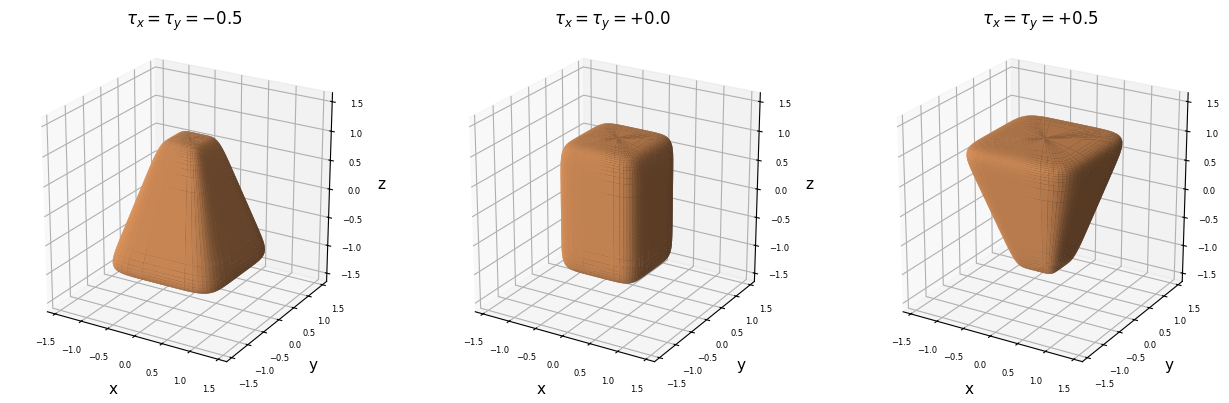

In [3]:
X=surface((.72,.72,1.1),(.24,.32));fig=plt.figure(figsize=(13,4))
for j,t in enumerate([-.5,0,.5]):
    ax=fig.add_subplot(1,3,j+1,projection='3d');plot3d(ax,taper(X,t,t,1.1),'#db935c');ax.set_title(r'$\tau_x=\tau_y=%+.1f$'%t)
fig.tight_layout();save(fig,'taper')

## 3. Bending: curvature $k$ and direction $\alpha$
Write $a=x\cos\alpha+y\sin\alpha$, $b=-x\sin\alpha+y\cos\alpha$, $\theta=kz$. For a bend around the $z$ axis,
$$a'=k^{-1}-(k^{-1}-a)\cos\theta,\qquad z'=(k^{-1}-a)\sin\theta,\qquad b'=b.$$
The arc radius is $1/|k|$. The direction $\alpha$ selects the azimuthal bending plane. The complete paper model composes *three* axis-bending operations.

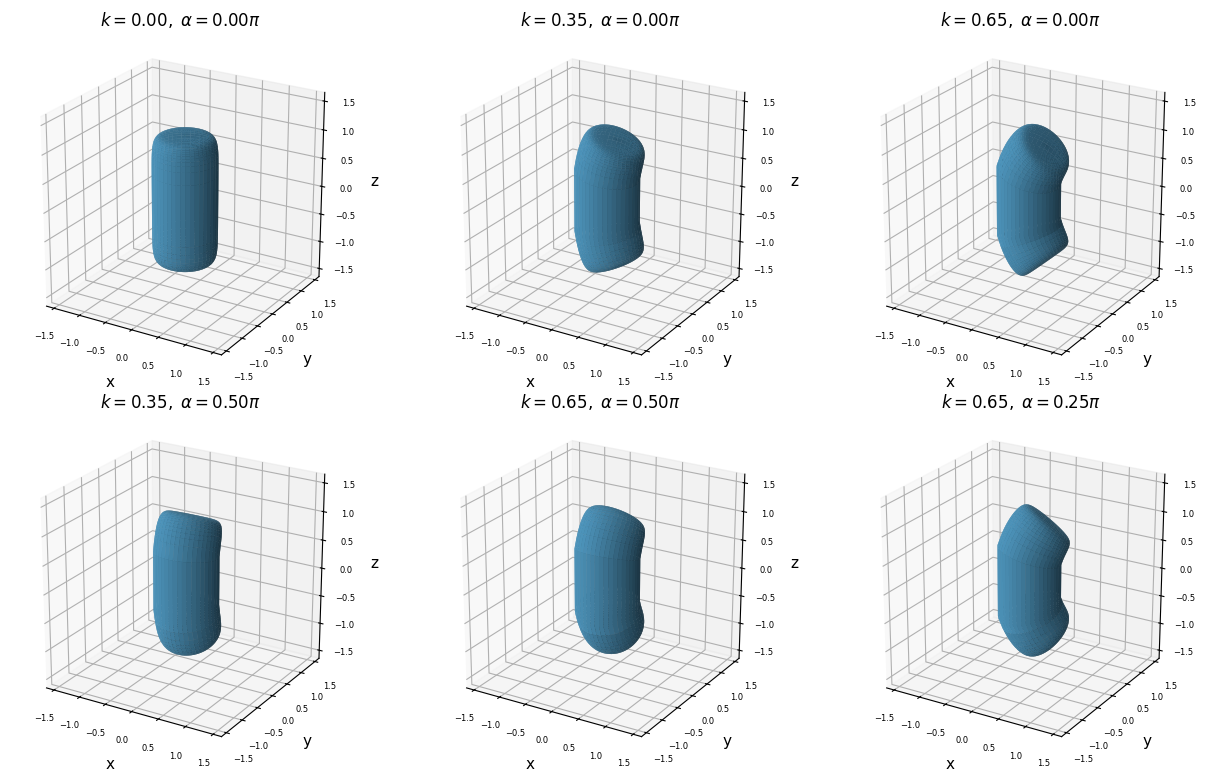

In [4]:
X=surface((.54,.54,1.12),(.24,1));fig=plt.figure(figsize=(13,7.8))
for j,(k,a) in enumerate([(0,0),(.35,0),(.65,0),(.35,np.pi/2),(.65,np.pi/2),(.65,np.pi/4)]):
    ax=fig.add_subplot(2,3,j+1,projection='3d');plot3d(ax,bend_z(X,k,a),'#4d94bb');ax.set_title(r'$k=%.2f,\;\alpha=%.2f\pi$'%(k,a/np.pi))
fig.tight_layout();save(fig,'bend')

## 4. A 19-parameter deformable primitive
$\Theta=\{t(3),R(3),s(3),\epsilon(2),\tau(2),\beta(6)\}$ (19 degrees of freedom). The inverse evaluation sequence is inverse world pose, then inverse bend $z,x,y$, then inverse taper, then canonical implicit function. The next plot combines a single-axis taper and bend for intuition.

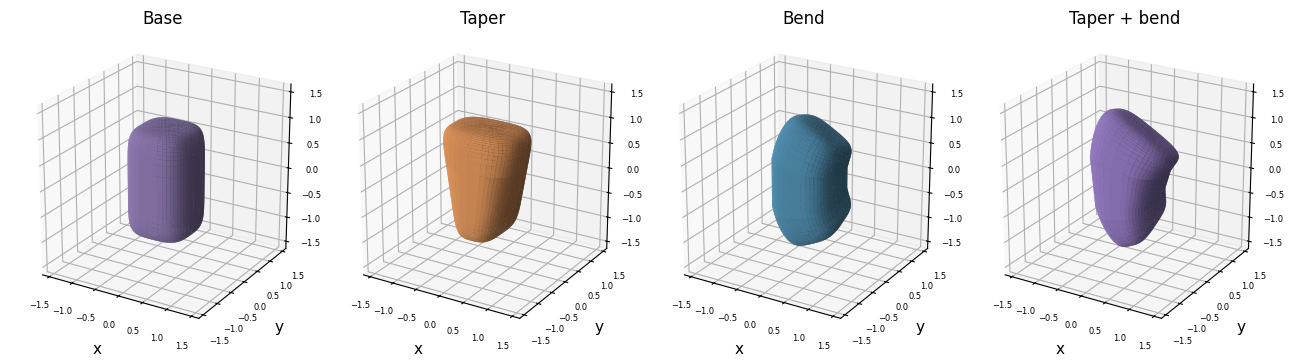

In [5]:
X=surface((.62,.62,1.05),(.32,.6))
variants=[('Base',X),('Taper',taper(X,.38,-.12,1.05)),('Bend',bend_z(X,.55,.6)),('Taper + bend',bend_z(taper(X,.38,-.12,1.05),.55,.6))]
fig=plt.figure(figsize=(13,4))
for j,(title,Y) in enumerate(variants):
    ax=fig.add_subplot(1,4,j+1,projection='3d');plot3d(ax,Y,['#907cb4','#de945b','#518eb0','#937bc2'][j]);ax.set_title(title)
fig.tight_layout();save(fig,'composition')

## 5. Radial versus Euclidean distance
For a *rigid* superellipsoid, $q(\lambda x)=\lambda^{2/\epsilon_1}q(x)$, hence the ray intersects $q=1$ at $\lambda_*=q(x)^{-\epsilon_1/2}$.
$$d_{rad}(x)=\|x\|\left(1-q(x)^{-\epsilon_1/2}\right).$$
Positive is outside, negative inside. This **radial** distance is not generally the shortest Euclidean distance. Under nonlinear deformations, $q$ loses homogeneity and the formula also becomes a surrogate for ray-intersection distance.

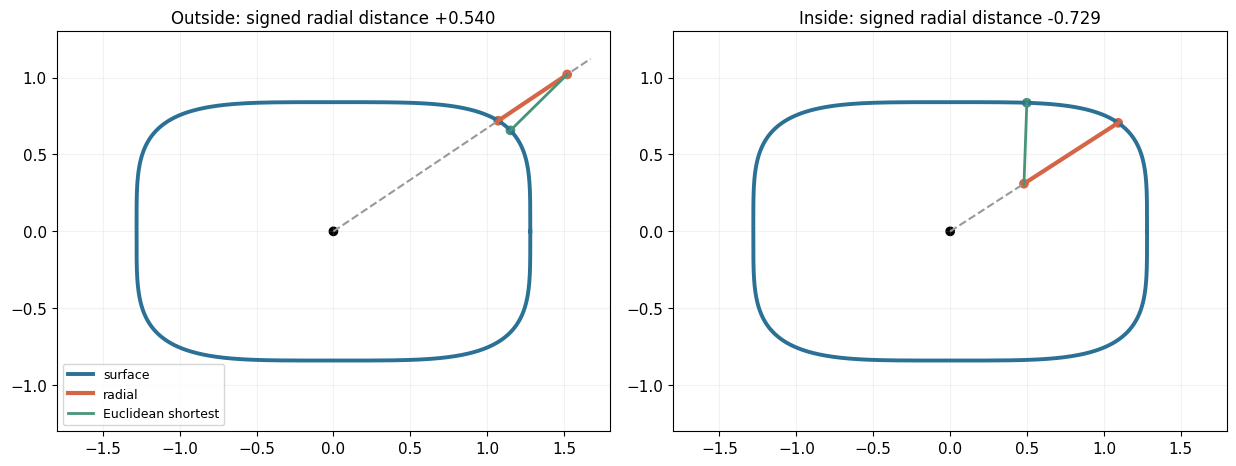

In [6]:
e=.48;a,b=1.28,.84;th=np.linspace(0,2*np.pi,2000)
curve=np.stack((a*spow(np.cos(th),e),b*spow(np.sin(th),e)),axis=-1)
fig,axes=plt.subplots(1,2,figsize=(12.5,5))
for ax,p,ttl in zip(axes,[(1.52,1.02),(.48,.31)],['Outside','Inside']):
    p=np.asarray(p);q=(abs(p[0]/a)**(2/e)+abs(p[1]/b)**(2/e));t=q**(-e/2);cross=t*p
    near=curve[np.argmin(np.sum((curve-p)**2,axis=1))];d=np.linalg.norm(p)*(1-t)
    ax.plot(curve[:,0],curve[:,1],lw=2.8,c='#2b7196',label='surface')
    ax.plot([0,p[0]*1.1],[0,p[1]*1.1],'--',c='0.6')
    ax.plot([p[0],cross[0]],[p[1],cross[1]],lw=3,c='#d56547',label='radial')
    ax.plot([p[0],near[0]],[p[1],near[1]],lw=2,c='#479477',label='Euclidean shortest')
    ax.scatter([0,p[0],cross[0],near[0]],[0,p[1],cross[1],near[1]],s=36,c=['black','#d56547','#d56547','#479477'])
    ax.set_title(f'{ttl}: signed radial distance {d:+.3f}')
    ax.set_aspect('equal');ax.grid(alpha=.16);ax.set(xlim=(-1.8,1.8),ylim=(-1.3,1.3))
axes[0].legend(fontsize=9,loc='lower left');fig.tight_layout();save(fig,'radial')

## 6. Homogeneity check after nonlinear tapering
Numerically solve $q_{def}(t x)=1$ along a ray. The paper's formula uses $q_{def}(x)^{-\epsilon_1/2}$ instead. These values need not coincide: this is a mathematical qualification, not a claim about empirical errors.

In [7]:
s=(1,.85,1);eps=(.5,.7);tx=.4;p=np.array([1.35,.35,.62])
qdef=lambda X: float(qcan(untaper(X,tx,0,s[2]),s,eps))
t=brentq(lambda a:qdef(a*p)-1,1e-5,2.)
formula=np.linalg.norm(p)*(1-qdef(p)**(-eps[0]/2));actual=np.linalg.norm(p)*(1-t)
print(f'Paper radial surrogate = {formula:.6f}; actual deformed ray distance = {actual:.6f}; |difference| = {abs(formula-actual):.6f}')

Paper radial surrogate = 0.177527; actual deformed ray distance = 0.209246; |difference| = 0.031719


## 7. Volumetric soft occupancy and union
$ I_p(x)=\sigma[-d_p(x)/T_{IoU}]$, and $\hat O(x)=1-\prod_p(1-e_p I_p(x))$. For two primitives it is the soft logical OR: $e_1I_1+e_2I_2-e_1e_2I_1I_2$. This illustration uses circles in 2D but the same identity holds in 3D.

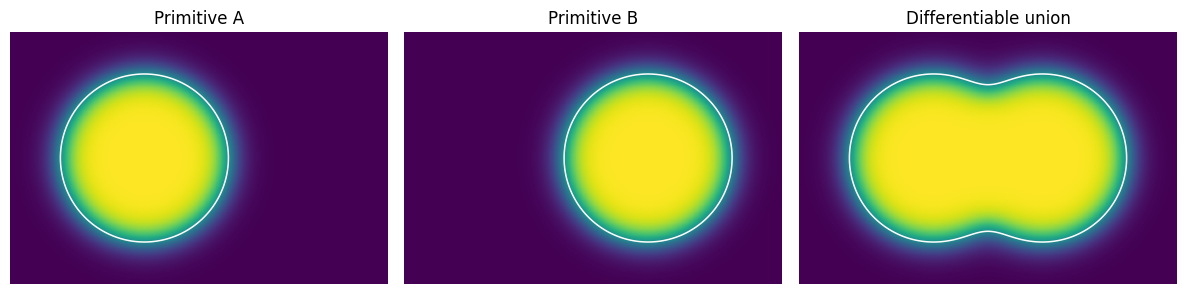

In [8]:
x=np.linspace(-1.8,1.8,310);y=np.linspace(-1.2,1.2,210);X,Y=np.meshgrid(x,y)
d1=np.hypot(X+.52,Y)-.8;d2=np.hypot(X-.52,Y)-.8;T=.08
I1=expit(-d1/T);I2=expit(-d2/T);U=1-(1-I1)*(1-I2)
fig,ax=plt.subplots(1,3,figsize=(12,3.6))
for a,data,title in zip(ax,[I1,I2,U],['Primitive A','Primitive B','Differentiable union']):
    a.imshow(data,origin='lower',extent=[-1.8,1.8,-1.2,1.2],vmin=0,vmax=1,cmap='viridis');a.contour(X,Y,data,[.5],colors='white',linewidths=1.1);a.set_title(title);a.axis('off')
fig.tight_layout();save(fig,'occupancy')

## 8. Robust surface loss
Appendix B.2: $L_{SDF}=N^{-1}\sum_{i,p} w_{ip}\psi(d(x_i;\Theta_p))$. The bounded signed activation is $\psi(d)=\delta\tanh(d/\delta)$ for $d\geq0$ and $\psi(d)=-\omega\delta\tanh(d/\delta)$ for $d<0$; $\delta=0.05$, selected $\omega=0.1$. Outside points are penalized more heavily when $\omega<1$.

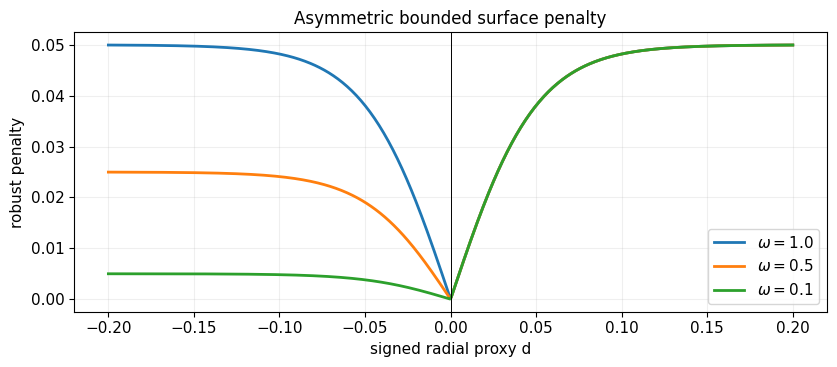

In [9]:
d=np.linspace(-.2,.2,600);delta=.05;fig,ax=plt.subplots(figsize=(8.5,3.8))
for omega in [1,.5,.1]:
    psi=np.where(d>=0,delta*np.tanh(d/delta),-omega*delta*np.tanh(d/delta))
    ax.plot(d,psi,lw=2,label=r'$\omega=%.1f$'%omega)
ax.axvline(0,color='k',lw=.7);ax.set(xlabel='signed radial proxy d',ylabel='robust penalty',title='Asymmetric bounded surface penalty');ax.legend();ax.grid(alpha=.2)
fig.tight_layout();save(fig,'psi')

## 9. Partial observations
A toy masking experiment to illustrate why structural priors are needed.SuperFlex's robust variant learns from complete pseudo-ground-truth primitive decompositions.

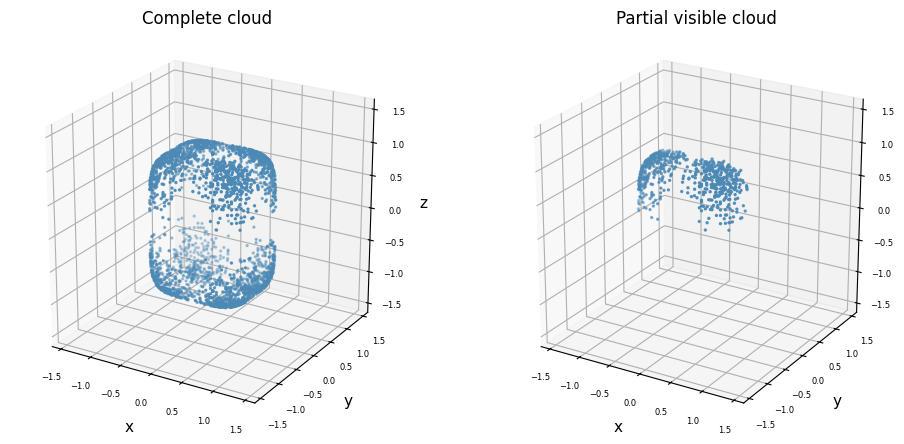

In [10]:
rng=np.random.default_rng(7);X=surface((.8,.67,1.05),(.35,.5),110,160).reshape(-1,3)
P=X[rng.choice(len(X),2600,replace=False)];V=P[(P[:,1]<-.05)&(P[:,2]>.0)]
fig=plt.figure(figsize=(10,4.5))
for j,(A,title) in enumerate([(P,'Complete cloud'),(V,'Partial visible cloud')]):
    ax=fig.add_subplot(1,2,j+1,projection='3d');ax.scatter(A[:,0],A[:,1],A[:,2],s=2,c='#4c89b5');equal3d(ax);ax.set_title(title)
fig.tight_layout();save(fig,'occlusion')